# Tahap 4 — Klasifikasi dengan *Machine Learning* Klasik

Tahap **Classification** dan **Evaluation** pada pipeline slide 10 materi Pertemuan 8. Model dilatih oleh
`scripts/04_train_ml.py` (logika di `src/models_ml.py`, metrik di `src/evaluate.py`); notebook ini hanya
memuat hasil dan menampilkan grafik.

**Protokol (anti-*leakage*)**
1. Pipeline `imblearn`: `StandardScaler → SelectKBest(f_classif) → [SMOTE] → classifier`; semua langkah di-*fit*
   hanya pada fold latih.
2. *Tuning*: `RandomizedSearchCV` (n_iter = 20, *scoring* ROC-AUC) **pada TRAIN saja** —
   A: StratifiedKFold 5-fold; B (data kecil): RepeatedStratifiedKFold 5×3. Varian penanganan *imbalance*
   (`class_weight='balanced'` vs SMOTE) dipilih berdasarkan AUC CV.
3. **VAL** dipakai untuk memilih ambang keputusan (Youden's J) dan memilih model terbaik antar-algoritma.
4. **TEST** dievaluasi **sekali** per model final; CI 95% AUC via *bootstrap* 1000×.
5. Variabilitas: *repeated stratified* CV 5×5 pada train (mean ± std).

Catatan: train A sudah di-*undersample* (healthy : COVID = 3 : 1), sedangkan val/test berdistribusi alami (≈1 : 14).
Karena itu **PR-AUC & precision harus dibandingkan dengan prevalensi test (≈0,066)**, bukan dengan 0,5.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings('ignore')

import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from src.config import load_config, set_seed
from src import evaluate as ev, models_ml as mm
from src.plots import (setup_style, save_fig, plot_roc_pr_all, plot_confusion, plot_importance_top,
                       plot_ablation, WARNA_MODEL)

cfg = load_config(); set_seed(); setup_style()
pd.set_option('display.precision', 3); pd.set_option('display.width', 160)
KOLOM = ['model', 'imbalance', 'cv_auc_mean', 'cv_auc_std', 'cvrep5x5_auc_mean', 'cvrep5x5_auc_std', 'val_auc',
         'roc_auc', 'roc_auc_ci_low', 'roc_auc_ci_high', 'pr_auc', 'threshold', 'recall_sensitivity',
         'specificity', 'precision', 'f1', 'balanced_accuracy', 'accuracy']

def tabel(exp):
    r = ev.load_results(exp)
    r = r[r['split'] == 'test']
    return r[KOLOM].sort_values('val_auc', ascending=False).reset_index(drop=True)

def muat(exp):
    objs = {a: joblib.load(cfg.paths.models / f'ml_{a}_{exp}.joblib') for a in mm.ALGORITMA}
    preds = pd.read_parquet(cfg.paths.models / f'preds_ml_{exp}.parquet')
    info = json.load(open(cfg.paths.logs / f'train_ml_{exp}_summary.json', encoding='utf-8'))
    return objs, preds, info

## Eksperimen A — `status` self-reported: COVID-19 vs healthy

### A.1 Tabel perbandingan model (TEST, ambang Youden dari VAL)
Diurutkan menurut AUC val (kriteria pemilihan). `cv_*` = CV di train (tuning); `cvrep5x5_*` = repeated stratified CV 5×5 di train dengan hyperparameter terbaik.

In [2]:
objs_A, preds_A, info_A = muat('A')
tab_A = tabel('A')
print('Model terbaik (AUC val):', info_A)
tab_A

Model terbaik (AUC val): {'eksperimen': 'A', 'model_terbaik': 'svm', 'imbalance': 'balanced', 'val_auc': 0.5742636626058025}


,model,imbalance,cv_auc_mean,cv_auc_std,cvrep5x5_auc_mean,cvrep5x5_auc_std,val_auc,roc_auc,roc_auc_ci_low,roc_auc_ci_high,pr_auc,threshold,recall_sensitivity,specificity,precision,f1,balanced_accuracy,accuracy
0,SVM (RBF),balanced,0.583,0.022,0.580,0.034,0.574,0.576,0.523,0.629,0.088,0.249,0.556,0.553,0.081,0.142,0.554,0.554
1,Logistic Regression,balanced,0.579,0.019,0.577,0.033,0.561,0.569,0.514,0.623,0.087,0.501,0.481,0.600,0.079,0.136,0.541,0.592
2,XGBoost,balanced,0.583,0.033,0.576,0.030,0.546,0.572,0.513,0.629,0.097,0.320,0.630,0.433,0.073,0.131,0.531,0.446
3,k-NN,none,0.570,0.026,0.564,0.029,0.542,0.580,0.525,0.636,0.088,0.270,0.509,0.613,0.086,0.147,0.561,0.607
4,Random Forest,balanced,0.586,0.033,0.583,0.033,0.527,0.570,0.513,0.628,0.091,0.493,0.407,0.705,0.090,0.147,0.556,0.685
5,Dummy (stratified),none,0.497,0.016,0.491,0.023,0.476,0.516,0.472,0.563,0.069,0.000,1.000,0.000,0.067,0.125,0.500,0.067


### A.2 Penanganan *imbalance*: `class_weight='balanced'` vs SMOTE
Varian dipilih berdasarkan AUC CV (train); kolom test hanya untuk dilaporkan, bukan untuk memilih.

In [3]:
pd.read_csv(cfg.paths.tables / '04_imbalance_A.csv').drop(columns='best_params')

,model,imbalance,dipilih,cv_auc_mean,cv_auc_std,val_auc,test_auc,test_sensitivity,test_specificity,test_f1,threshold
0,Dummy (stratified),none,True,0.497,0.016,0.476,0.516,1.000,0.000,0.125,0.000
1,Logistic Regression,balanced,True,0.579,0.019,0.561,0.569,0.481,0.600,0.136,0.501
2,Logistic Regression,smote,False,0.574,0.010,0.554,0.576,0.361,0.716,0.135,0.526
3,SVM (RBF),balanced,True,0.583,0.022,0.574,0.576,0.556,0.553,0.142,0.249
4,SVM (RBF),smote,False,0.579,0.035,0.551,0.556,0.296,0.718,0.113,0.545
5,k-NN,none,True,0.570,0.026,0.542,0.580,0.509,0.613,0.147,0.270
6,k-NN,smote,False,0.563,0.036,0.558,0.553,0.759,0.286,0.129,0.500
7,Random Forest,balanced,True,0.586,0.033,0.527,0.570,0.407,0.705,0.147,0.493
8,Random Forest,smote,False,0.585,0.030,0.552,0.582,0.370,0.747,0.151,0.537
9,XGBoost,balanced,True,0.583,0.033,0.546,0.572,0.630,0.433,0.131,0.320


### A.3 Kurva ROC & Precision–Recall semua model (TEST)

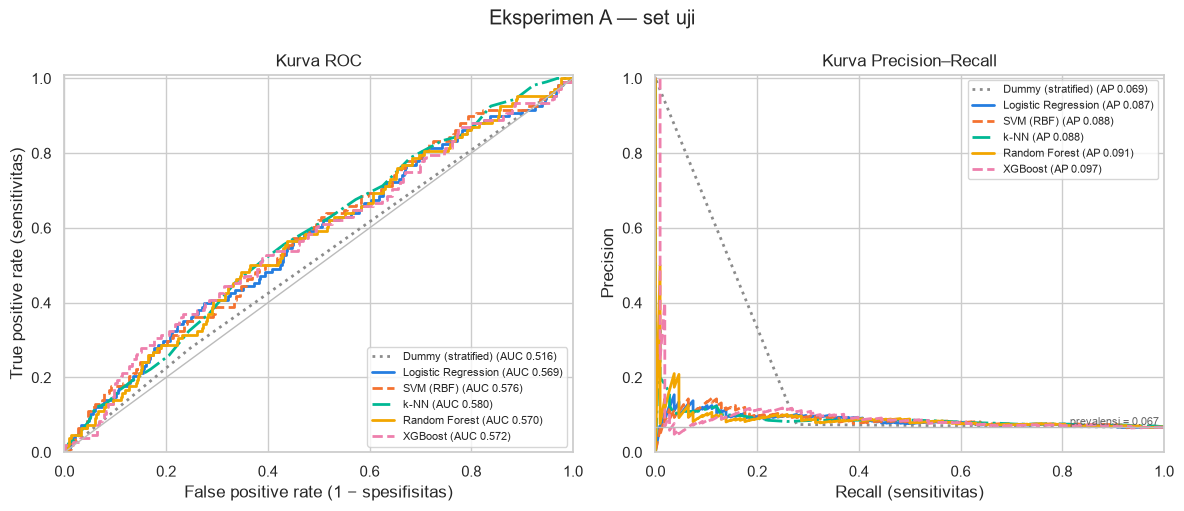

In [4]:
te = preds_A[preds_A.split == 'test']
scores = {mm.NAMA_MODEL[a]: te[a].to_numpy() for a in mm.ALGORITMA}
fig = plot_roc_pr_all(te['label'].to_numpy(), scores, title='Eksperimen A — set uji')
save_fig(fig, '04_roc_pr_A'); plt.show()

### A.4 *Confusion matrix* model terbaik (TEST)
Kiri: ambang Youden yang dipilih di VAL (dipakai di tabel). Kanan: ambang default 0,5 sebagai pembanding.

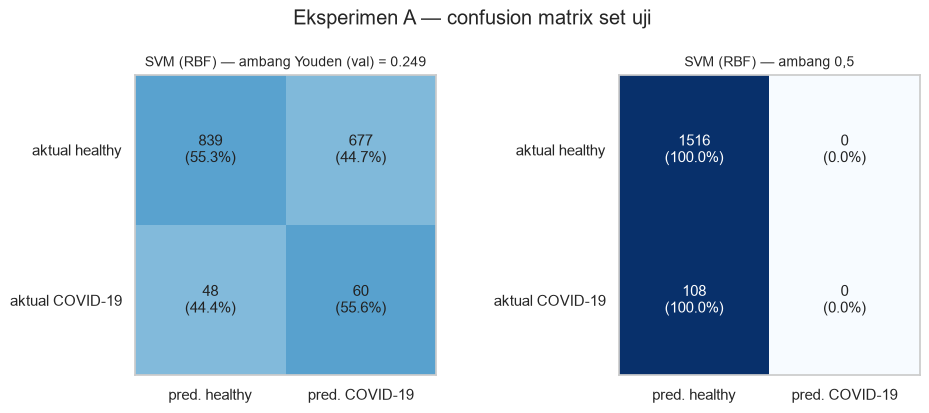

In [5]:
b = info_A['model_terbaik']; o = objs_A[b]
y, s = te['label'].to_numpy(), te[b].to_numpy()
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
plot_confusion(ev.confusion(y, s, o['threshold']), f"{mm.NAMA_MODEL[b]} — ambang Youden (val) = {o['threshold']:.3f}", ax=axes[0])
plot_confusion(ev.confusion(y, s, 0.5), f"{mm.NAMA_MODEL[b]} — ambang 0,5", ax=axes[1])
fig.suptitle('Eksperimen A — confusion matrix set uji'); fig.tight_layout()
save_fig(fig, '04_confusion_A'); plt.show()

### A.5 *Feature importance* top-20
RF: *mean decrease impurity*; XGBoost: *gain*; permutasi: penurunan ROC-AUC di **VAL** saat satu fitur diacak (10 ulangan, model terbaik). Importance bawaan hanya untuk fitur yang lolos SelectKBest.

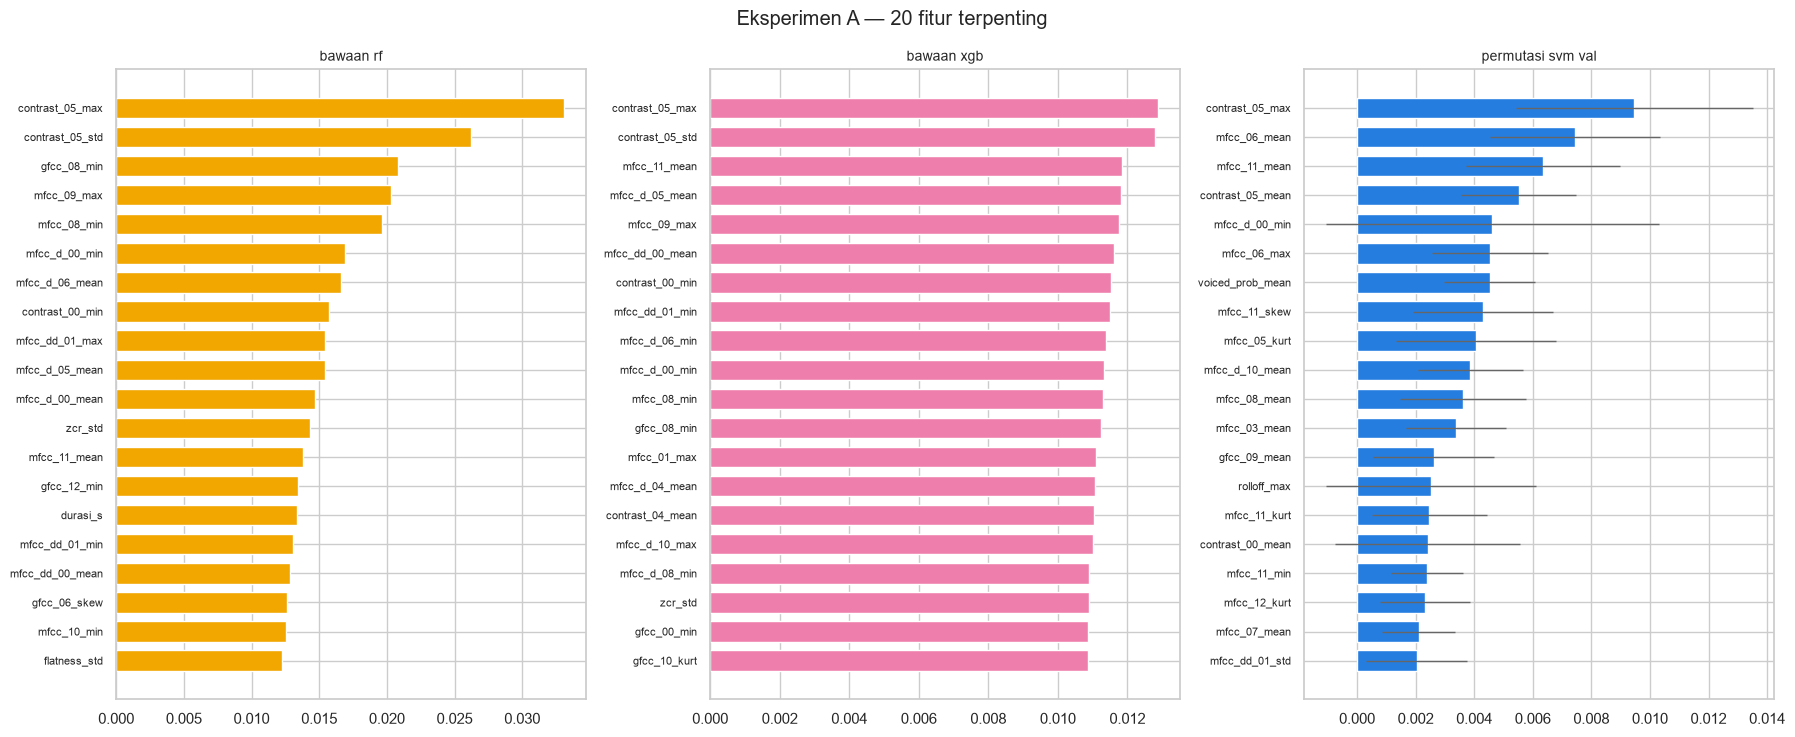

Kelompok fitur pada top-20 permutasi: {'MFCC': 11, 'spektral': 4, 'MFCC delta': 2, 'pitch': 1, 'GFCC': 1, 'MFCC delta-delta': 1}


In [6]:
imp = pd.read_csv(cfg.paths.tables / '04_importance_A.csv')
metode = [m for m in imp.metode.unique()]
fig, axes = plt.subplots(1, len(metode), figsize=(6 * len(metode), 7.5))
warna = ['#f2a600', '#ee7fac', '#257de0']
for ax, m, w in zip(np.atleast_1d(axes), metode, warna):
    plot_importance_top(imp[imp.metode == m], title=m.replace('_', ' '), ax=ax, color=w)
fig.suptitle('Eksperimen A — 20 fitur terpenting'); fig.tight_layout()
save_fig(fig, '04_importance_A'); plt.show()
perm = imp[imp.metode.str.startswith('permutasi')].nlargest(20, 'importance')
print('Kelompok fitur pada top-20 permutasi:', perm.kelompok.value_counts().to_dict())

### A.6 Ablasi fitur (model terbaik, *tuning* ulang per subset, n_iter = 10)

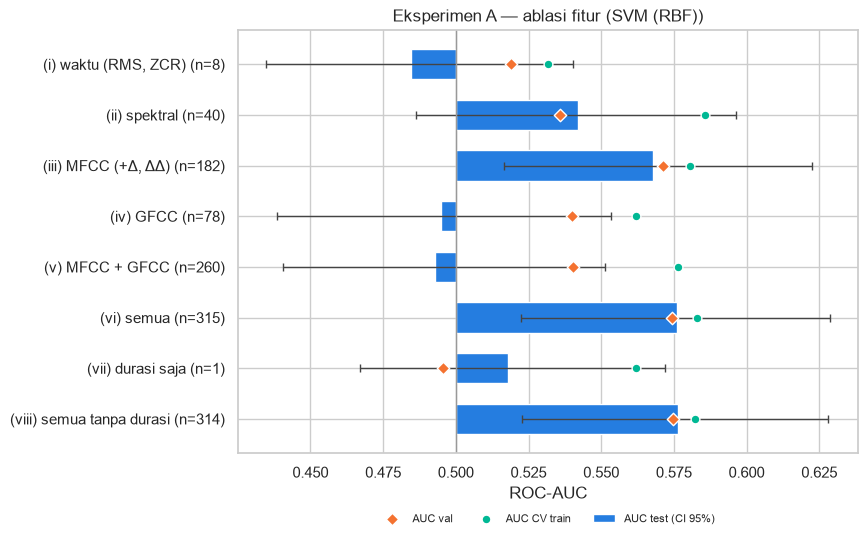

,subset,n_fitur,cv_auc_mean,val_auc,test_auc,test_auc_ci_low,test_auc_ci_high,test_pr_auc,test_sensitivity,test_specificity,test_f1
0,"(i) waktu (RMS, ZCR)",8,0.532,0.519,0.485,0.435,0.540,0.062,0.472,0.508,0.113
1,(ii) spektral,40,0.586,0.536,0.542,0.486,0.596,0.073,0.806,0.280,0.135
2,"(iii) MFCC (+Δ, ΔΔ)",182,0.581,0.571,0.568,0.516,0.623,0.085,0.361,0.724,0.138
3,(iv) GFCC,78,0.562,0.540,0.495,0.438,0.553,0.068,0.639,0.344,0.118
4,(v) MFCC + GFCC,260,0.576,0.540,0.493,0.441,0.551,0.065,0.435,0.542,0.111
5,(vi) semua,315,0.583,0.574,0.576,0.523,0.629,0.088,0.556,0.553,0.142
6,(vii) durasi saja,1,0.562,0.495,0.518,0.467,0.572,0.066,0.074,0.895,0.058
7,(viii) semua tanpa durasi,314,0.582,0.575,0.576,0.523,0.628,0.089,0.546,0.564,0.143


In [7]:
abl_A = pd.read_csv(cfg.paths.tables / '04_ablasi_fitur.csv')
fig = plot_ablation(abl_A, title=f"Eksperimen A — ablasi fitur ({abl_A.model[0]})")
save_fig(fig, '04_ablasi_A'); plt.show()
abl_A[['subset', 'n_fitur', 'cv_auc_mean', 'val_auc', 'test_auc', 'test_auc_ci_low', 'test_auc_ci_high',
         'test_pr_auc', 'test_sensitivity', 'test_specificity', 'test_f1']]

## Eksperimen B — label ahli (majority vote `diagnosis_*`): COVID-19 vs healthy_cough

### B.1 Tabel perbandingan model (TEST, ambang Youden dari VAL)
Diurutkan menurut AUC val (kriteria pemilihan). `cv_*` = CV di train (tuning); `cvrep5x5_*` = repeated stratified CV 5×5 di train dengan hyperparameter terbaik.

In [8]:
objs_B, preds_B, info_B = muat('B')
tab_B = tabel('B')
print('Model terbaik (AUC val):', info_B)
tab_B

Model terbaik (AUC val): {'eksperimen': 'B', 'model_terbaik': 'svm', 'imbalance': 'smote', 'val_auc': 0.7183098591549296}


,model,imbalance,cv_auc_mean,cv_auc_std,cvrep5x5_auc_mean,cvrep5x5_auc_std,val_auc,roc_auc,roc_auc_ci_low,roc_auc_ci_high,pr_auc,threshold,recall_sensitivity,specificity,precision,f1,balanced_accuracy,accuracy
0,SVM (RBF),smote,0.768,0.033,0.766,0.035,0.718,0.826,0.745,0.888,0.786,0.557,0.743,0.805,0.765,0.754,0.774,0.776
1,XGBoost,balanced,0.754,0.040,0.753,0.045,0.713,0.807,0.726,0.871,0.754,0.586,0.614,0.817,0.741,0.672,0.716,0.724
2,Logistic Regression,balanced,0.768,0.032,0.767,0.035,0.712,0.812,0.730,0.877,0.749,0.554,0.771,0.817,0.783,0.777,0.794,0.796
3,Random Forest,smote,0.749,0.040,0.748,0.040,0.685,0.817,0.741,0.879,0.771,0.488,0.800,0.732,0.718,0.757,0.766,0.763
4,k-NN,none,0.726,0.036,0.723,0.033,0.648,0.776,0.689,0.848,0.675,0.539,0.629,0.756,0.688,0.657,0.692,0.697
5,Dummy (stratified),none,0.503,0.045,0.487,0.054,0.428,0.487,0.417,0.567,0.454,0.000,1.000,0.000,0.461,0.631,0.500,0.461


### B.2 Penanganan *imbalance*: `class_weight='balanced'` vs SMOTE
Varian dipilih berdasarkan AUC CV (train); kolom test hanya untuk dilaporkan, bukan untuk memilih.

In [9]:
pd.read_csv(cfg.paths.tables / '04_imbalance_B.csv').drop(columns='best_params')

,model,imbalance,dipilih,cv_auc_mean,cv_auc_std,val_auc,test_auc,test_sensitivity,test_specificity,test_f1,threshold
0,Dummy (stratified),none,True,0.503,0.045,0.428,0.487,1.000,0.000,0.631,0.000
1,Logistic Regression,balanced,True,0.768,0.032,0.712,0.812,0.771,0.817,0.777,0.554
2,Logistic Regression,smote,False,0.767,0.032,0.710,0.816,0.743,0.854,0.776,0.558
3,SVM (RBF),balanced,False,0.767,0.033,0.711,0.817,0.771,0.756,0.750,0.468
4,SVM (RBF),smote,True,0.768,0.033,0.718,0.826,0.743,0.805,0.754,0.557
5,k-NN,none,True,0.726,0.036,0.648,0.776,0.629,0.756,0.657,0.539
6,k-NN,smote,False,0.725,0.035,0.662,0.784,0.800,0.695,0.742,0.552
7,Random Forest,balanced,False,0.746,0.041,0.686,0.814,0.800,0.720,0.752,0.464
8,Random Forest,smote,True,0.749,0.040,0.685,0.817,0.800,0.732,0.757,0.488
9,XGBoost,balanced,True,0.754,0.040,0.713,0.807,0.614,0.817,0.672,0.586


### B.3 Kurva ROC & Precision–Recall semua model (TEST)

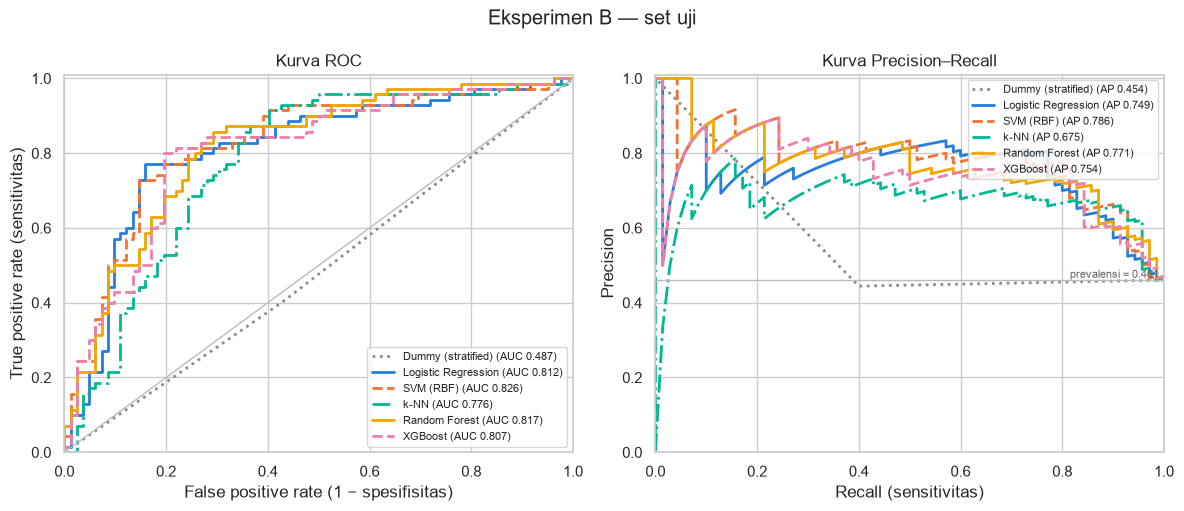

In [10]:
te = preds_B[preds_B.split == 'test']
scores = {mm.NAMA_MODEL[a]: te[a].to_numpy() for a in mm.ALGORITMA}
fig = plot_roc_pr_all(te['label'].to_numpy(), scores, title='Eksperimen B — set uji')
save_fig(fig, '04_roc_pr_B'); plt.show()

### B.4 *Confusion matrix* model terbaik (TEST)
Kiri: ambang Youden yang dipilih di VAL (dipakai di tabel). Kanan: ambang default 0,5 sebagai pembanding.

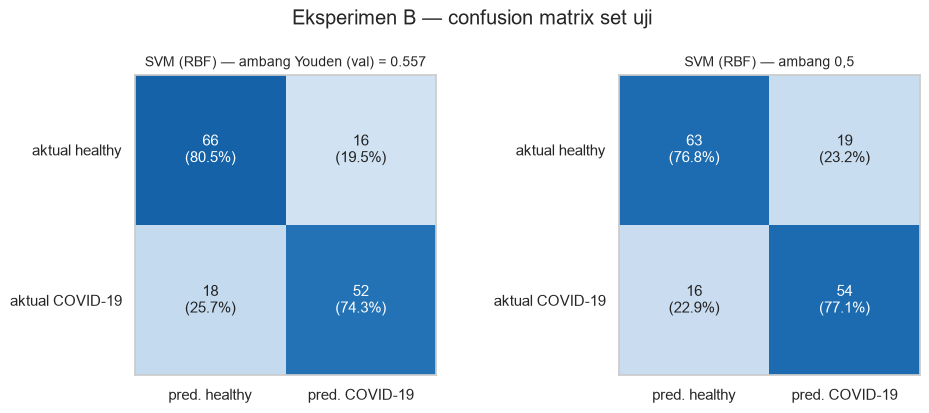

In [11]:
b = info_B['model_terbaik']; o = objs_B[b]
y, s = te['label'].to_numpy(), te[b].to_numpy()
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
plot_confusion(ev.confusion(y, s, o['threshold']), f"{mm.NAMA_MODEL[b]} — ambang Youden (val) = {o['threshold']:.3f}", ax=axes[0])
plot_confusion(ev.confusion(y, s, 0.5), f"{mm.NAMA_MODEL[b]} — ambang 0,5", ax=axes[1])
fig.suptitle('Eksperimen B — confusion matrix set uji'); fig.tight_layout()
save_fig(fig, '04_confusion_B'); plt.show()

### B.5 *Feature importance* top-20
RF: *mean decrease impurity*; XGBoost: *gain*; permutasi: penurunan ROC-AUC di **VAL** saat satu fitur diacak (10 ulangan, model terbaik). Importance bawaan hanya untuk fitur yang lolos SelectKBest.

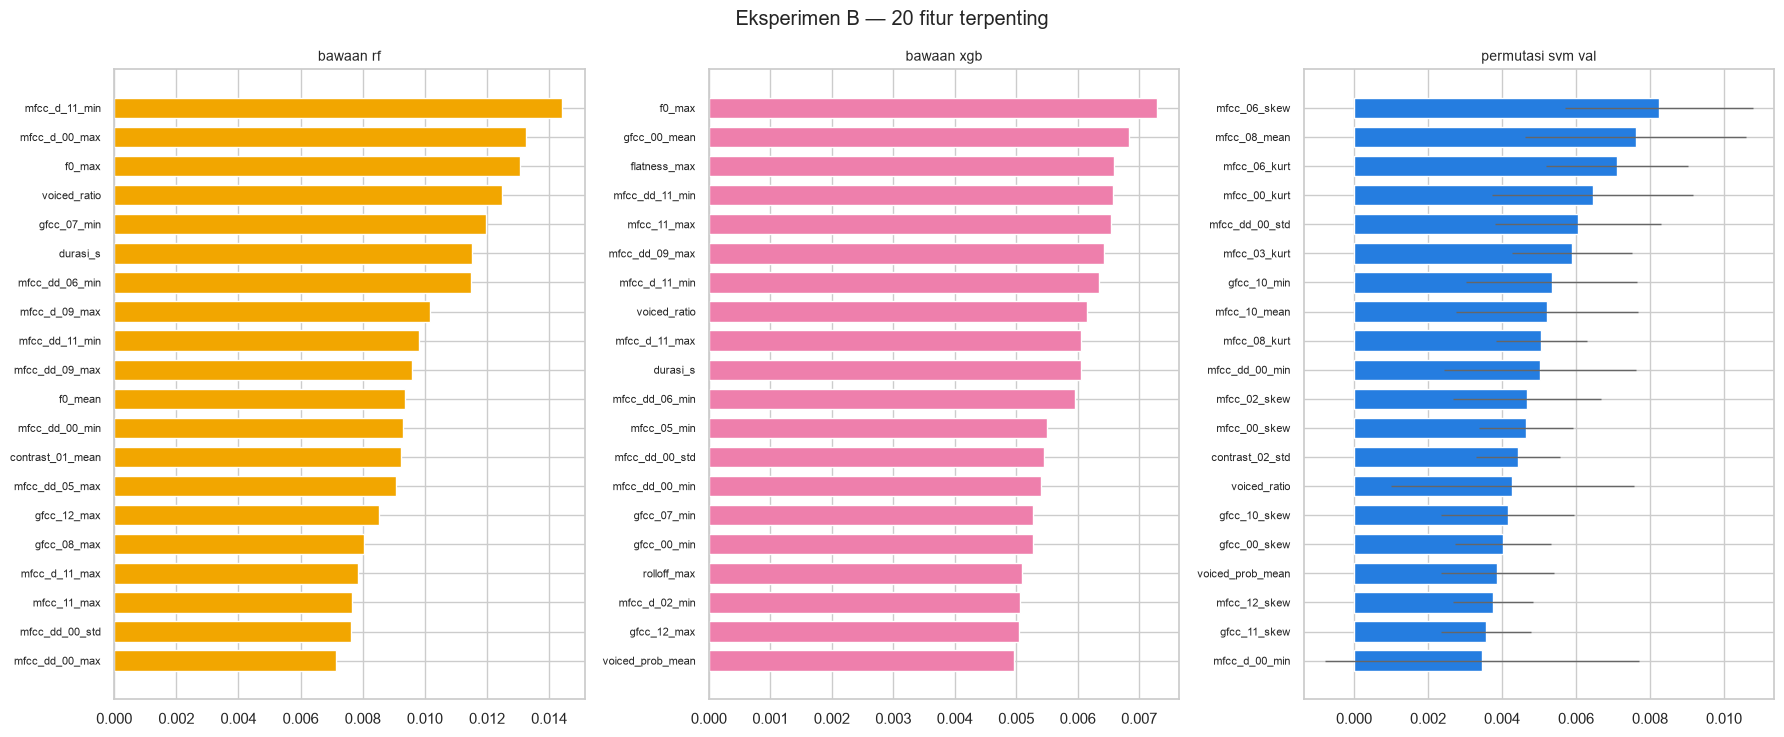

Kelompok fitur pada top-20 permutasi: {'MFCC': 10, 'GFCC': 4, 'MFCC delta-delta': 2, 'pitch': 2, 'spektral': 1, 'MFCC delta': 1}


In [12]:
imp = pd.read_csv(cfg.paths.tables / '04_importance_B.csv')
metode = [m for m in imp.metode.unique()]
fig, axes = plt.subplots(1, len(metode), figsize=(6 * len(metode), 7.5))
warna = ['#f2a600', '#ee7fac', '#257de0']
for ax, m, w in zip(np.atleast_1d(axes), metode, warna):
    plot_importance_top(imp[imp.metode == m], title=m.replace('_', ' '), ax=ax, color=w)
fig.suptitle('Eksperimen B — 20 fitur terpenting'); fig.tight_layout()
save_fig(fig, '04_importance_B'); plt.show()
perm = imp[imp.metode.str.startswith('permutasi')].nlargest(20, 'importance')
print('Kelompok fitur pada top-20 permutasi:', perm.kelompok.value_counts().to_dict())

### B.6 Ablasi fitur (model terbaik, *tuning* ulang per subset, n_iter = 10)

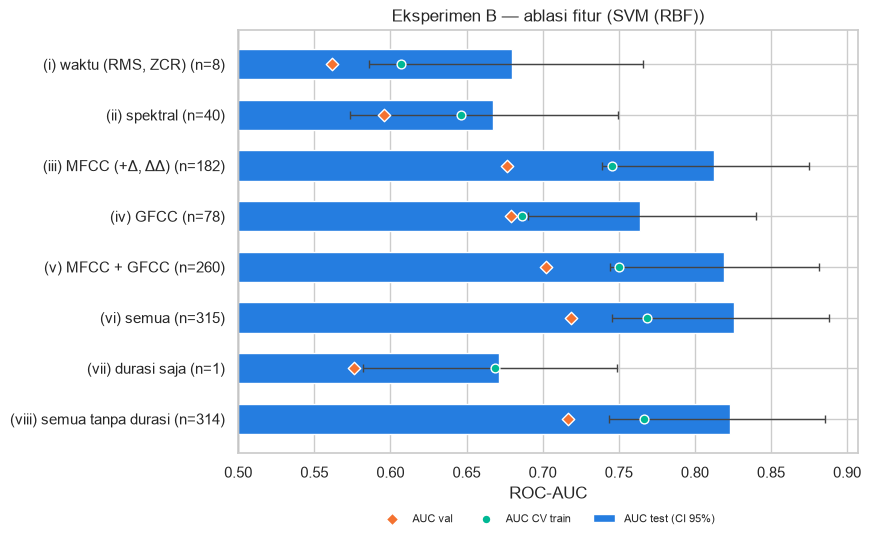

,subset,n_fitur,cv_auc_mean,val_auc,test_auc,test_auc_ci_low,test_auc_ci_high,test_pr_auc,test_sensitivity,test_specificity,test_f1
0,"(i) waktu (RMS, ZCR)",8,0.607,0.562,0.680,0.586,0.766,0.667,0.486,0.744,0.544
1,(ii) spektral,40,0.646,0.596,0.667,0.574,0.750,0.576,0.443,0.695,0.492
2,"(iii) MFCC (+Δ, ΔΔ)",182,0.745,0.676,0.813,0.739,0.875,0.757,0.886,0.573,0.743
3,(iv) GFCC,78,0.686,0.679,0.764,0.690,0.840,0.663,0.600,0.768,0.641
4,(v) MFCC + GFCC,260,0.750,0.702,0.819,0.744,0.882,0.773,0.571,0.854,0.656
5,(vi) semua,315,0.768,0.718,0.826,0.745,0.888,0.786,0.743,0.805,0.754
6,(vii) durasi saja,1,0.669,0.576,0.671,0.582,0.749,0.579,0.743,0.463,0.627
7,(viii) semua tanpa durasi,314,0.767,0.716,0.823,0.744,0.885,0.777,0.714,0.829,0.746


In [13]:
abl_B = pd.read_csv(cfg.paths.tables / '04_ablasi_fitur_B.csv')
fig = plot_ablation(abl_B, title=f"Eksperimen B — ablasi fitur ({abl_B.model[0]})")
save_fig(fig, '04_ablasi_B'); plt.show()
abl_B[['subset', 'n_fitur', 'cv_auc_mean', 'val_auc', 'test_auc', 'test_auc_ci_low', 'test_auc_ci_high',
         'test_pr_auc', 'test_sensitivity', 'test_specificity', 'test_f1']]

## Ringkasan A vs B

In [14]:
ring = pd.concat([tabel('A').assign(eksp='A'), tabel('B').assign(eksp='B')])
ring.pivot_table(index='model', columns='eksp', values=['roc_auc', 'cvrep5x5_auc_mean', 'recall_sensitivity', 'specificity', 'f1'])

cvrep5x5_auc_mean            f1        recall_sensitivity        roc_auc        specificity       
eksp                                A      B      A      B                  A      B       A      B           A      B
model                                                                                                                 
Dummy (stratified)              0.491  0.487  0.125  0.631              1.000  1.000   0.516  0.487       0.000  0.000
Logistic Regression             0.577  0.767  0.136  0.777              0.481  0.771   0.569  0.812       0.600  0.817
Random Forest                   0.583  0.748  0.147  0.757              0.407  0.800   0.570  0.817       0.705  0.732
SVM (RBF)                       0.580  0.766  0.142  0.754              0.556  0.743   0.576  0.826       0.553  0.805
XGBoost                         0.576  0.753  0.131  0.672              0.630  0.614   0.572  0.807       0.433  0.817
k-NN                            0.564  0.723  0.147  0.657              0.509  0.629   0.580  0.776       0.613  0.756

## Interpretasi

**1. Eksperimen A (label *self-reported*) hampir tidak dapat dipisahkan.** Semua model ML klasik berada pada
ROC-AUC test **0,57–0,58** (CI 95% ≈ 0,51–0,64), hanya sedikit di atas baseline Dummy (0,52) dan sesuai
ekspektasi Tahap 3 (overlap kelas besar, silhouette ≈ 0). CI semua model saling tumpang-tindih → **tidak ada
algoritma yang terbukti lebih baik**; pemilihan SVM sebagai "terbaik" (AUC val 0,574) bersifat lemah.
PR-AUC ≈ 0,09 dan *precision* ≈ 0,08 hanya sedikit di atas prevalensi test (0,066): pada skrining nyata, dari
setiap ±12 rekaman yang ditandai positif hanya ±1 yang benar COVID-19 (*self-reported*). Model ini **tidak
layak** sebagai alat skrining.

**2. Eksperimen B (label ahli) jauh lebih terpisah.** Dengan fitur dan pipeline yang sama, AUC test naik ke
**0,78–0,83** (SVM 0,826 [0,745–0,888]; LogReg 0,812) dan *repeated* CV 5×5 di train **0,72–0,77 ± 0,04**.
Ini mendukung R4 (Xiong dkk., 2022): kualitas label membatasi performa lebih kuat daripada pilihan algoritma.
*Caveat*: subset B berbeda populasi (rekaman yang dipilih untuk dianotasi ahli, kelas seimbang), test hanya
152 rekaman (CI lebar ±0,07), dan AUC test B lebih tinggi daripada val/CV → sebagian karena variasi sampel kecil.
Label "ahli" pun dibuat dari mendengarkan batuk (bukan PCR), sehingga model B sebagian besar belajar meniru
penilaian akustik pulmonolog, bukan diagnosis virologis.

**3. Penanganan *imbalance*.** `class_weight='balanced'` vs SMOTE berbeda ≤ 0,01 AUC CV untuk semua algoritma
(lihat tabel A.2/B.2) — AUC tidak dipengaruhi pembobotan kelas secara langsung; pilihan ini lebih berpengaruh
pada kalibrasi/ambang. Ambang Youden dipilih di val sehingga sensitivitas & spesifisitas di test seimbang (A ≈ 0,4–0,6).

**4. Fitur.** Fitur yang paling berguna konsisten dengan uji Mann-Whitney Tahap 3: **kontras spektral pita
tinggi** (`contrast_05_*`, ±3,2–6,4 kHz) dan **MFCC** (statistik koefisien tengah–tinggi, c6–c11) untuk A;
untuk B, **statistik bentuk distribusi MFCC (skew/kurt) dan dinamika MFCC (Δ/ΔΔ)** serta pitch (`f0_max`,
`voiced_ratio`). Fitur domain waktu murni (RMS, ZCR) hampir tidak informatif (ablasi A: AUC test 0,49).

**5. Shortcut durasi.** Ablasi menunjukkan model **tanpa `durasi_s`** praktis sama dengan semua fitur
(A 0,576 vs 0,576; B 0,823 vs 0,826) → model tidak bergantung pada durasi. "Durasi saja" memberi AUC test
0,52 (A) dan **0,67 (B)**: di B durasi memang membawa informasi kelas (healthy_cough lebih pendek), sehingga
perlu disebut sebagai *confounder* potensial di laporan.

**6. Ablasi kelompok fitur.** Di B, MFCC (+Δ, ΔΔ) sendiri sudah mendekati performa penuh (0,813), GFCC sedikit
lebih rendah (0,764), dan kombinasi MFCC+GFCC tidak menambah banyak (0,819) → informasi MFCC dan GFCC sangat
redundan (keduanya representasi *cepstral* dari *filterbank* berskala persepsi). Di A semua subset berada
di 0,49–0,58 dengan CI lebar, sehingga perbedaan antar-subset tidak bermakna.
